In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import copy
import random
import math
import numpy as np
import pandas as pd

# Your project imports
from tsn_scheduling_problem import TSNScheduling
from schedule import Schedule, Slot

# Benchmark utilities you already have
from benchmark_utils import (
    build_network_generator_from_usecase,
    generate_one_arrival_stream,
    build_usecase_stream_from_request,
)

# Optional: cleaner printing
np.set_printoptions(suppress=True, linewidth=140)

print("Imports loaded.")

Imports loaded.


In [5]:
CONFIG_PATH = "uc_config.cfg"
INSTANCE_PATH = "banana3.json"   # change if you want another instance

problem = TSNScheduling(CONFIG_PATH)
instance = problem.import_scheduling_usecase(INSTANCE_PATH)

# Keep problem aligned with this instance
problem.usecase = instance
problem.build_metadata()

print("Loaded instance:", INSTANCE_PATH)
print("Number of streams in usecase:", len(instance.streams))
print("Number of scheduled slots:", len(instance.schedule))

active_stream_ids = sorted({
    int(slot.stream_id)
    for slot in instance.schedule
    if slot.stream_id is not None
})

print("Active scheduled streams:", len(active_stream_ids))
print("Active stream IDs:", active_stream_ids)
print("Cycle ns:", instance.schedule.cycle_ns)

Loaded instance: banana3.json
Number of streams in usecase: 62
Number of scheduled slots: 18
Active scheduled streams: 5
Active stream IDs: [4, 14, 23, 24, 38]
Cycle ns: 300000


In [6]:
from evaluator import TSNConstraintEvaluator, ScheduleEncodingType

def check_schedule_validity(instance, problem, label="schedule"):
    """
    Check whether the current instance.schedule has evaluator violations.
    """
    problem.usecase = instance
    problem.build_metadata()

    evaluator = TSNConstraintEvaluator(
        problem,
        check_routing=False,
        check_task_placement=False,
        scheduling_type=ScheduleEncodingType.START_TIME,
    )

    compact = instance.schedule.to_compact_encoding(
        problem.n_ports,
        problem.n_streams,
    )

    violations = evaluator.per_stream_all_violations(compact)

    breakdown = {
        "seq": int(violations[0].sum()) if violations.shape[0] > 0 else 0,
        "fifo": int(violations[1].sum()) if violations.shape[0] > 1 else 0,
        "macrocycle": int(violations[2].sum()) if violations.shape[0] > 2 else 0,
        "talker_offset": int(violations[3].sum()) if violations.shape[0] > 3 else 0,
        "latency": int(violations[4].sum()) if violations.shape[0] > 4 else 0,
        "total": int(violations.sum()),
    }

    print(f"[{label}] violation breakdown:", breakdown)
    return breakdown

validity = check_schedule_validity(instance, problem, label="initial")

[initial] violation breakdown: {'seq': 0, 'fifo': 0, 'macrocycle': 0, 'talker_offset': 0, 'latency': 0, 'total': 0}


In [7]:
DRL_MODEL_PATH_V27 = "runs/run_41_trace_env_smoke/best_model"

DRL_TRAIN_CONFIG_V27 = {
    "max_candidates": 10,
    "max_hops": 6,
    "max_steps": 500,

    "init_from_usecase_schedule": True,
    "include_current_offset_candidate": True,

    "per_hop_candidate_limit": 5,
    "beam_width": 30,

    "defrag_cycle_penalty": 0.6,
    "reallocation_penalty": 0.1,
    "invalid_penalty": 10.0,

    "useless_gap_threshold_bytes": 1024,
    "expected_incoming_bytes": 1024,

    "top_k_oldest_random": 10,
}

In [8]:
from stable_baselines3 import DQN
from env import TSNCandidatePathEnv


def make_drl_eval_env(
    instance,
    problem,
    seed=42,
    lambda_arrival=0.75,
    decision_points_per_episode=300,
    cfg=None,
):
    cfg = cfg or DRL_TRAIN_CONFIG_V27

    prob = copy.deepcopy(problem)
    inst = copy.deepcopy(instance)
    prob.usecase = inst
    prob.build_metadata()

    env = TSNCandidatePathEnv(
        problem=prob,
        usecase=inst,
        useless_gap_threshold_bytes=cfg["useless_gap_threshold_bytes"],
        expected_incoming_bytes=cfg["expected_incoming_bytes"],
        invalid_penalty=cfg["invalid_penalty"],
        max_candidates=cfg["max_candidates"],
        max_steps=cfg["max_steps"],
        max_hops=cfg["max_hops"],
        init_from_usecase_schedule=cfg["init_from_usecase_schedule"],
        include_current_offset_candidate=cfg["include_current_offset_candidate"],
        per_hop_candidate_limit=cfg["per_hop_candidate_limit"],
        beam_width=cfg["beam_width"],
        defrag_cycle_penalty=cfg["defrag_cycle_penalty"],
        reallocation_penalty=cfg["reallocation_penalty"],
        lambda_arrival=lambda_arrival,
        mu_departure=1.0,  # not very important for shared-trace mode, but keep stable
        dt=1.0,
        decision_points_per_episode=decision_points_per_episode,
        top_k_oldest_random=cfg["top_k_oldest_random"],
        seed=seed,
    )

    return env


def check_drl_model_env_compatibility(model_path, instance, problem, cfg=None):
    env = make_drl_eval_env(
        instance=instance,
        problem=problem,
        seed=42,
        lambda_arrival=0.75,
        decision_points_per_episode=300,
        cfg=cfg,
    )

    model = DQN.load(model_path)

    print("Model observation space:")
    print(model.observation_space)

    print("\nEval env observation space:")
    print(env.observation_space)

    print("\nModel action space:")
    print(model.action_space)

    print("\nEval env action space:")
    print(env.action_space)

    print("\nObservation spaces equal:", model.observation_space == env.observation_space)
    print("Action spaces equal:", model.action_space == env.action_space)

    return model, env

model_check, env_check = check_drl_model_env_compatibility(
    model_path=DRL_MODEL_PATH_V27,
    instance=instance,
    problem=problem,
    cfg=DRL_TRAIN_CONFIG_V27,
)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Model observation space:
Dict('base_features': Box(-1.0, 1.0, (7,), float32), 'candidate_features': Box(-1.0, 1.0, (5, 4), float32), 'candidate_mask': Box(0, 1, (6,), int8), 'candidate_offsets': Box(-1.0, 1.0, (5, 6), float32), 'current_offsets': Box(-1.0, 1.0, (6,), float32))

Eval env observation space:
Dict('base_features': Box(-1.0, 1.0, (7,), float32), 'candidate_features': Box(-1.0, 1.0, (10, 4), float32), 'candidate_mask': Box(0, 1, (11,), int8), 'candidate_offsets': Box(-1.0, 1.0, (10, 6), float32), 'current_offsets': Box(-1.0, 1.0, (6,), float32))

Model action space:
Discrete(6)

Eval env action space:
Discrete(11)

Observation spaces equal: False
Action spaces equal: False


In [9]:
def generate_long_decision_trace(
    instance,
    max_steps=10000,
    lambda_arrival=1.0,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
):
    """
    Generate a long shared trace for decision-point experiments.

    Each step contains:
      - n_dep = 1 departure opportunity
      - arrivals sampled from Poisson(lambda_arrival * dt)

    The runner decides when to stop based on actual departures.
    """
    rng_np = np.random.default_rng(seed)

    ng = build_network_generator_from_usecase(copy.deepcopy(instance))

    trace = []

    for _ in range(int(max_steps)):
        n_arr = int(rng_np.poisson(lambda_arrival * dt))

        arrivals = []
        for _ in range(n_arr):
            raw_stream = generate_one_arrival_stream(
                ng,
                ed_ed_settings=ed_ed_settings,
            )
            arrivals.append(raw_stream)

        trace.append({
            "n_dep": 1,
            "arrivals": arrivals,
        })

    return trace


In [10]:
def get_active_stream_ids(schedule):
    return sorted({
        int(slot.stream_id)
        for slot in schedule
        if slot.stream_id is not None
    })


def build_port_intervals(schedule):
    relevant_ports = sorted({
        int(slot.port_id)
        for slot in schedule
        if slot.port_id is not None
    })

    return {
        pid: schedule._occupied_intervals_on_port(pid, schedule.cycle_ns)
        for pid in relevant_ports
    }


def init_stream_arrival_times(schedule):
    """
    Initial streams are considered already present at time 0.
    """
    return {
        int(sid): 0.0
        for sid in get_active_stream_ids(schedule)
    }


def summarize_decisions(decisions):
    """
    decisions maps arrival_id -> one of:
      accept, scheduler_reject, raw_none, build_none
    """
    counts = {
        "accept": 0,
        "scheduler_reject": 0,
        "raw_none": 0,
        "build_none": 0,
    }

    for v in decisions.values():
        if v in counts:
            counts[v] += 1
        else:
            counts[v] = counts.get(v, 0) + 1

    return counts


def batch_left_compact_streams_preserve_id(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Clean batch left-compaction with preserved stream IDs.

    Steps:
      1. Backup full schedule and stream metadata.
      2. Remove all selected stream slots as a batch.
      3. Reinsert each selected stream using preserve-ID first-fit-fast.
      4. If any stream fails, rollback everything.
      5. Return moved stream IDs.
    """
    import copy

    stream_ids = [int(sid) for sid in stream_ids]

    if not stream_ids:
        return {
            "success": True,
            "moved_stream_ids": [],
            "failed_stream_ids": [],
        }

    # Full backup for rollback
    old_schedule_slots = copy.deepcopy(list(schedule))
    old_streams = copy.deepcopy(usecase.streams)

    old_offsets = {
        sid: sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )
        for sid in stream_ids
    }

    # Check all streams exist and are scheduled
    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

        if not old_offsets.get(sid):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

    selected_set = set(stream_ids)

    # Remove all selected stream slots together
    schedule[:] = [
        slot for slot in schedule
        if slot.stream_id is None or int(slot.stream_id) not in selected_set
    ]
    schedule.sort()

    # Rebuild intervals after batch removal
    if port_intervals is not None:
        port_intervals.clear()
        port_intervals.update(build_port_intervals(schedule))

    problem.usecase = usecase
    problem.build_metadata()

    failed_stream_ids = []

    for sid in stream_ids:
        result = schedule.place_existing_stream_first_fit_fast(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            failed_stream_ids.append(sid)
            break

    if failed_stream_ids:
        # Full rollback
        schedule[:] = old_schedule_slots
        schedule.sort()

        usecase.streams = old_streams

        problem.usecase = usecase
        problem.build_metadata()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        usecase.removeSchedule()
        _, port_id_to_name = usecase.port_name_id_mapping
        usecase.schedule = schedule
        schedule.update_graph(usecase.graph, port_id_to_name)

        return {
            "success": False,
            "moved_stream_ids": [],
            "failed_stream_ids": failed_stream_ids,
        }

    # Count real moved streams
    moved_stream_ids = []

    for sid in stream_ids:
        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if old_offsets.get(sid, []) != new_offsets:
            moved_stream_ids.append(sid)

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": [],
    }


def batch_right_compact_streams_preserve_id(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=5,
    beam_width=3,
):
    """
    Clean batch right-compaction with preserved stream IDs.

    Steps:
      1. Backup full schedule and stream metadata.
      2. Remove all selected stream slots as a batch.
      3. Reinsert each selected stream using preserve-ID right-fit.
      4. If any stream fails, rollback everything.
      5. Return moved stream IDs.
    """
    import copy

    stream_ids = [int(sid) for sid in stream_ids]

    if not stream_ids:
        return {
            "success": True,
            "moved_stream_ids": [],
            "failed_stream_ids": [],
        }

    old_schedule_slots = copy.deepcopy(list(schedule))
    old_streams = copy.deepcopy(usecase.streams)

    old_offsets = {
        sid: sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )
        for sid in stream_ids
    }

    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

        if not old_offsets.get(sid):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

    selected_set = set(stream_ids)

    schedule[:] = [
        slot for slot in schedule
        if slot.stream_id is None or int(slot.stream_id) not in selected_set
    ]
    schedule.sort()

    if port_intervals is not None:
        port_intervals.clear()
        port_intervals.update(build_port_intervals(schedule))

    problem.usecase = usecase
    problem.build_metadata()

    failed_stream_ids = []

    for sid in stream_ids:
        result = schedule.place_existing_stream_right_fit_backward(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            failed_stream_ids.append(sid)
            break

    if failed_stream_ids:
        schedule[:] = old_schedule_slots
        schedule.sort()

        usecase.streams = old_streams

        problem.usecase = usecase
        problem.build_metadata()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        usecase.removeSchedule()
        _, port_id_to_name = usecase.port_name_id_mapping
        usecase.schedule = schedule
        schedule.update_graph(usecase.graph, port_id_to_name)

        return {
            "success": False,
            "moved_stream_ids": [],
            "failed_stream_ids": failed_stream_ids,
        }

    moved_stream_ids = []

    for sid in stream_ids:
        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if old_offsets.get(sid, []) != new_offsets:
            moved_stream_ids.append(sid)

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": [],
    }


def oldest_first_left_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    OF-LC(p,n): Oldest-First Left-Compaction with preserved stream IDs.

    Every p departures:
      1. Select n oldest active streams.
      2. Remove them as a batch.
      3. Reinsert them from the left using preserve-ID first-fit-fast.
      4. Roll back if the batch cannot be fully reinserted.
    """
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = batch_left_compact_streams_preserve_id(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", []) if result.get("success") else []

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": result.get("success", False),
        "failed_stream_ids": result.get("failed_stream_ids", []),
    }


def oldest_first_right_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=5,
    beam_width=3,
):
    """
    OF-RC(p,n): Oldest-First Right-Compaction with preserved stream IDs.

    Every p departures:
      1. Select n oldest active streams.
      2. Remove them as a batch.
      3. Reinsert them from the right using backward right-fit.
      4. Roll back if the batch cannot be fully reinserted.
    """
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = batch_right_compact_streams_preserve_id(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", []) if result.get("success") else []

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": result.get("success", False),
        "failed_stream_ids": result.get("failed_stream_ids", []),
    }


def place_new_stream_with_existing_fast(
    schedule,
    stream,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Place a new arrival stream using the preserve-ID existing-stream placement.

    This replaces schedule.place_stream_first_fit_fast(...).
    """
    import copy

    stream_id = len(usecase.streams)

    # Append new stream definition first, so metadata/evaluator knows it exists
    usecase.streams.append(copy.deepcopy(stream))

    result = schedule.place_existing_stream_first_fit_fast(
        stream_id=stream_id,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    if result.get("accepted"):
        return result

    # If rejected, remove the appended stream definition again
    usecase.streams.pop()
    problem.usecase = usecase
    problem.build_metadata()

    return {
        "accepted": [],
        "rejected": [stream_id],
    }


def get_stream_slots(schedule, stream_id):
    return sorted(
        [
            slot for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == int(stream_id)
        ],
        key=lambda s: int(s.start_ns),
    )


def get_stream_offsets(schedule, stream_id):
    return [
        int(slot.start_ns)
        for slot in get_stream_slots(schedule, stream_id)
    ]

print("Helper functions loaded.")

Helper functions loaded.


In [11]:
def run_no_defrag_decision_trace(
    instance,
    problem,
    trace,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Run No-Defrag on a shared long trace.

    Episode stops when actual departures reach decision_points_per_episode.
    Arrivals are whatever occurred during those trace steps.
    """
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

        # -------------------------
        # Arrivals after departure
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "decisions": decisions,
    }


In [12]:
def run_of_lc_preserve_id_decision_trace(
    instance,
    problem,
    trace,
    p=20,
    n=5,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    successful_defrag_cycles = 0
    failed_defrag_cycles = 0
    actual_reallocations = 0

    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            # Trigger OF-LC every p actual departures
            while (
                p > 0
                and n > 0
                and next_defrag_trigger is not None
                and total_departures >= next_defrag_trigger
            ):
                defrag_result = oldest_first_left_compact_defrag_preserve_id(
                    schedule=sched,
                    usecase=inst,
                    problem=prob,
                    p=1,
                    n=n,
                    departure_counter=1,
                    queue_id=5,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                    max_candidates_per_hop=max_candidates_per_hop,
                    beam_width=beam_width,
                )

                if defrag_result.get("triggered", False):
                    actual_defrag_cycles += 1

                    if defrag_result.get("success", False):
                        successful_defrag_cycles += 1
                        actual_reallocations += int(defrag_result.get("replaced_count", 0))
                    else:
                        failed_defrag_cycles += 1

                next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(successful_defrag_cycles),
        "failed_defrag_cycles": int(failed_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,
    }

In [13]:
def run_of_rc_preserve_id_decision_trace(
    instance,
    problem,
    trace,
    p=8,
    n=10,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=5,
    beam_width=3,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    successful_defrag_cycles = 0
    failed_defrag_cycles = 0
    actual_reallocations = 0

    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            while (
                p > 0
                and n > 0
                and next_defrag_trigger is not None
                and total_departures >= next_defrag_trigger
            ):
                defrag_result = oldest_first_right_compact_defrag_preserve_id(
                    schedule=sched,
                    usecase=inst,
                    problem=prob,
                    p=1,
                    n=n,
                    departure_counter=1,
                    queue_id=5,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                    max_candidates_per_hop=max_candidates_per_hop,
                    beam_width=beam_width,
                )

                if defrag_result.get("triggered", False):
                    actual_defrag_cycles += 1

                    if defrag_result.get("success", False):
                        successful_defrag_cycles += 1
                        actual_reallocations += int(defrag_result.get("replaced_count", 0))
                    else:
                        failed_defrag_cycles += 1

                next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=2,
                beam_width=1,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(successful_defrag_cycles),
        "failed_defrag_cycles": int(failed_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,
    }

In [14]:
def run_of_ff_decision_trace(
    instance,
    problem,
    trace,
    p=8,
    n=10,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Run OF-FF on a shared long trace.

    Episode stops when actual departures reach decision_points_per_episode.
    OF-FF triggers every p actual departures.
    """
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    actual_reallocations = 0
    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            # Trigger OF-FF every p actual departures.
            while (
                p > 0
                and n > 0
                and next_defrag_trigger is not None
                and total_departures >= next_defrag_trigger
            ):
                defrag_result = sched.oldest_first_first_fit_defrag(
                    usecase=inst,
                    problem=prob,
                    p=1,                    # force trigger
                    n=n,
                    departure_counter=1,     # force trigger
                    queue_id=5,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )

                if defrag_result.get("triggered", False):
                    actual_defrag_cycles += 1
                    actual_reallocations += int(defrag_result.get("replaced_count", 0))

                next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,
    }

In [15]:
from stable_baselines3 import DQN
from env import TSNCandidatePathEnv
import torch

def run_drl_decision_trace(
    instance,
    problem,
    trace,
    model_path,
    decision_points_per_episode=300,
    seed=42,

    # Arrival scheduler params
    max_candidates_per_hop=2,
    beam_width=1,

    # DRL/env params
    drl_cfg=None,
    deterministic=True,
    max_actions_per_decision=100,
    debug=False,
    debug_max_decisions=3,
):
    drl_cfg = drl_cfg or DRL_TRAIN_CONFIG_V27

    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    model = DQN.load(model_path)

    env = TSNCandidatePathEnv(
        problem=copy.deepcopy(prob),
        usecase=copy.deepcopy(inst),
        useless_gap_threshold_bytes=drl_cfg["useless_gap_threshold_bytes"],
        expected_incoming_bytes=drl_cfg["expected_incoming_bytes"],
        invalid_penalty=drl_cfg["invalid_penalty"],
        max_candidates=drl_cfg["max_candidates"],
        max_steps=drl_cfg["max_steps"],
        max_hops=drl_cfg["max_hops"],
        init_from_usecase_schedule=drl_cfg["init_from_usecase_schedule"],
        include_current_offset_candidate=drl_cfg["include_current_offset_candidate"],
        per_hop_candidate_limit=drl_cfg["per_hop_candidate_limit"],
        beam_width=drl_cfg["beam_width"],
        defrag_cycle_penalty=drl_cfg["defrag_cycle_penalty"],
        reallocation_penalty=drl_cfg["reallocation_penalty"],
        lambda_arrival=0.0,
        mu_departure=0.0,
        dt=1.0,
        decision_points_per_episode=decision_points_per_episode,
        top_k_oldest_random=drl_cfg["top_k_oldest_random"],
        seed=seed,
    )

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    actual_reallocations = 0
    invalid_moves = 0

    decisions = {}

    debug_decisions_seen = 0

    def sync_env_from_current_schedule():
        """
        Sync DRL env with the externally controlled benchmark state.
        """
        env.usecase = inst
        env.problem = prob
        env.problem.usecase = inst
        env.problem.build_metadata()
        env._rebuild_runtime_metadata()

        env._load_state_from_schedule(sched)
        env.usecase.schedule = sched
        env.port_intervals = build_port_intervals(sched)

        env.stream_arrival_times = dict(stream_arrival_times)
        env.current_time = float(step_count)
        env.in_defrag_cycle = False
        env.decision_active = False
        env.current_candidates = []

    def run_one_drl_decision():
        nonlocal actual_defrag_cycles
        nonlocal actual_reallocations
        nonlocal invalid_moves
        nonlocal debug_decisions_seen
        
        moved_this_decision = False

        sync_env_from_current_schedule()
        #diag_df = diagnose_drl_candidate_generation(env, n_decisions=1)
        #display(diag_df[["stream_id", "path_len", "candidate_count", "current_offsets", "candidate_offsets"]])

        active = env._active_stream_ids()
        if not active:
            return

        env.decision_stream_order = env._ordered_streams_by_age()
        env.decision_pointer = 0

        if not env.decision_stream_order:
            return

        env.focus.stream_id = int(env.decision_stream_order[0])
        env.current_candidates = env._candidate_list_for_stream(
            int(env.focus.stream_id)
        )
        env.decision_active = True
        env.in_defrag_cycle = False

        if debug and debug_decisions_seen < debug_max_decisions:
            print("\n[DRL decision]")
            print("Active streams:", len(active))
            print("Decision order:", env.decision_stream_order[:10])

        for action_step in range(max_actions_per_decision):
            obs = env._get_obs()
            action, _ = model.predict(obs, deterministic=deterministic)
            if debug and debug_decisions_seen < debug_max_decisions:
                obs_tensor, _ = model.policy.obs_to_tensor(obs)

                with torch.no_grad():
                    q_values = model.q_net(obs_tensor)
                    q_values = q_values.cpu().numpy().flatten()

                valid_mask = obs["candidate_mask"].astype(bool)

                print("  Q-values:")
                for a_idx, q in enumerate(q_values):
                    valid_txt = "valid" if valid_mask[a_idx] else "pad"
                    name = "STOP" if a_idx == 0 else f"CAND {a_idx - 1}"
                    print(f"    action {a_idx} ({name:6s}, {valid_txt}) Q={q:.4f}")
            action = int(np.asarray(action).item())

            # padded/non-existing candidate => STOP
            if action > 0:
                cand_idx = action - 1
                if cand_idx < 0 or cand_idx >= len(env.current_candidates):
                    action = 0

            if debug and debug_decisions_seen < debug_max_decisions:
                print(
                    f"  focus={env.focus.stream_id}, "
                    f"cands={len(env.current_candidates)}, "
                    f"action={action}"
                )

            # STOP
            if action == 0:
                break

            cand = env.current_candidates[action - 1]

            saved_ports = copy.deepcopy(env.port_schedules)
            saved_offsets = copy.deepcopy(env.stream_offsets)

            applied = env._apply_stream_move(
                cand.stream_id,
                cand.offsets,
            )

            if not applied:
                invalid_moves += 1
                env.port_schedules = saved_ports
                env.stream_offsets = saved_offsets
                env._sync_usecase_schedule()
                env._sync_evaluator_with_schedule_durations()
                break

            violation_sum = env._violation_sum()

            if violation_sum != 0:
                invalid_moves += 1
                env.port_schedules = saved_ports
                env.stream_offsets = saved_offsets
                env._sync_usecase_schedule()
                env._sync_evaluator_with_schedule_durations()
                break

            # Valid move
            if not env.in_defrag_cycle:
                env.in_defrag_cycle = True
                actual_defrag_cycles += 1

            actual_reallocations += 1
            moved_this_decision = True

            env._backup_current_as_last_valid()
            env._advance_stream_focus()

            if env.decision_pointer >= len(env.decision_stream_order):
                break

            env.current_candidates = env._candidate_list_for_stream(
                int(env.focus.stream_id)
            )

            if not env.current_candidates:
                # no candidates for current focus; continue to next focus
                env._advance_stream_focus()
                if env.decision_pointer >= len(env.decision_stream_order):
                    break
                env.current_candidates = env._candidate_list_for_stream(
                    int(env.focus.stream_id)
                )

        # Commit only if a move occurred
        if moved_this_decision:
            new_sched = env.get_combined_schedule()
            sched[:] = list(new_sched)
            sched.sort()

            inst.schedule = sched
            port_intervals.clear()
            port_intervals.update(build_port_intervals(sched))

        debug_decisions_seen += 1

    for step in trace:
        step_count += 1

        # -------------------------
        # Departures
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            # DRL decision after departure event
            run_one_drl_decision()

        # -------------------------
        # Arrivals
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)

            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),

        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),

        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(actual_defrag_cycles),
        "failed_defrag_cycles": 0,
        "reallocations": int(actual_reallocations),
        "invalid_moves": int(invalid_moves),

        "decisions": decisions,
    }

In [16]:
def compare_decision_dicts(no_decisions, of_decisions):
    """
    Compare per-arrival decisions between No-Defrag and OF-FF.

    We treat only 'accept' as accepted.
    Everything else is rejected.
    """
    all_ids = sorted(set(no_decisions.keys()) | set(of_decisions.keys()))

    both_accept = []
    both_reject = []
    of_gain = []
    of_damage = []
    missing = []

    for aid in all_ids:
        if aid not in no_decisions or aid not in of_decisions:
            missing.append(aid)
            continue

        no_acc = no_decisions[aid] == "accept"
        of_acc = of_decisions[aid] == "accept"

        if no_acc and of_acc:
            both_accept.append(aid)
        elif (not no_acc) and (not of_acc):
            both_reject.append(aid)
        elif (not no_acc) and of_acc:
            of_gain.append(aid)
        elif no_acc and (not of_acc):
            of_damage.append(aid)

    summary = {
        "both_accept": both_accept,
        "both_reject": both_reject,
        "of_gain": of_gain,
        "of_damage": of_damage,
        "missing": missing,
        "net_gain": len(of_gain) - len(of_damage),
    }

    print(f"Both accept: {len(both_accept)}")
    print(f"Both reject: {len(both_reject)}")
    print(f"OF gain    : {len(of_gain)} {of_gain[:30]}")
    print(f"OF damage  : {len(of_damage)} {of_damage[:30]}")
    print(f"Missing    : {len(missing)}")
    print(f"Net gain   : {summary['net_gain']}")

    return summary


In [17]:
def benchmark_decision_points(
    instance,
    problem,
    n_episodes=10,
    decision_points_per_episode=100,
    lambda_arrival=1.0,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
    max_trace_steps=10000,
    p=8,
    n=10,
    p2=20,
    n2=5,
    max_candidates_per_hop=2,
    beam_width=1,
):
    results = {
        "no_defrag_sbr": [],
        "no_defrag_scheduler_sbr": [],
        "no_defrag_acc": [],
        "no_defrag_arrivals": [],
        "no_defrag_departures": [],
        "no_defrag_scheduler_rejected": [],

        "of_ff_sbr": [],
        "of_ff_scheduler_sbr": [],
        "of_ff_acc": [],
        "of_ff_arrivals": [],
        "of_ff_departures": [],
        "of_ff_scheduler_rejected": [],
        "of_ff_cycles": [],
        "of_ff_reallocations": [],
        "of_ff_net_gain": [],
        "of_ff_gain": [],
        "of_ff_damage": [],

        "of_ff2_sbr": [],
        "of_ff2_scheduler_sbr": [],
        "of_ff2_acc": [],
        "of_ff2_arrivals": [],
        "of_ff2_departures": [],
        "of_ff2_scheduler_rejected": [],
        "of_ff2_cycles": [],
        "of_ff2_reallocations": [],
        "of_ff2_net_gain": [],
        "of_ff2_gain": [],
        "of_ff2_damage": [],

        "episode_details": [],
    }

    for ep in range(int(n_episodes)):
        ep_seed = int(seed) + ep

        trace = generate_long_decision_trace(
            instance=instance,
            max_steps=max_trace_steps,
            lambda_arrival=lambda_arrival,
            dt=dt,
            seed=ep_seed,
            ed_ed_settings=ed_ed_settings,
        )

        res_no = run_no_defrag_decision_trace(
            instance=instance,
            problem=problem,
            trace=trace,
            decision_points_per_episode=decision_points_per_episode,
            seed=ep_seed,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        res_ff = run_of_ff_decision_trace(
            instance=instance,
            problem=problem,
            trace=trace,
            p=p,
            n=n,
            decision_points_per_episode=decision_points_per_episode,
            seed=ep_seed,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        res_ff2 = run_of_ff_decision_trace(
            instance=instance,
            problem=problem,
            trace=trace,
            p=p2,
            n=n2,
            decision_points_per_episode=decision_points_per_episode,
            seed=ep_seed,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        cmp_ff = compare_decision_dicts(
            res_no["decisions"],
            res_ff["decisions"],
        )

        cmp_ff2 = compare_decision_dicts(
            res_no["decisions"],
            res_ff2["decisions"],
        )

        # Store No-Defrag
        results["no_defrag_sbr"].append(res_no["sbr"])
        results["no_defrag_scheduler_sbr"].append(res_no["scheduler_sbr"])
        results["no_defrag_acc"].append(res_no["acceptance"])
        results["no_defrag_arrivals"].append(res_no["arrivals"])
        results["no_defrag_departures"].append(res_no["departures"])
        results["no_defrag_scheduler_rejected"].append(res_no["scheduler_rejected"])

        # Store OF-FF
        results["of_ff_sbr"].append(res_ff["sbr"])
        results["of_ff_scheduler_sbr"].append(res_ff["scheduler_sbr"])
        results["of_ff_acc"].append(res_ff["acceptance"])
        results["of_ff_arrivals"].append(res_ff["arrivals"])
        results["of_ff_departures"].append(res_ff["departures"])
        results["of_ff_scheduler_rejected"].append(res_ff["scheduler_rejected"])
        results["of_ff_cycles"].append(res_ff["defrag_cycles"])
        results["of_ff_reallocations"].append(res_ff["reallocations"])
        results["of_ff_gain"].append(len(cmp_ff["of_gain"]))
        results["of_ff_damage"].append(len(cmp_ff["of_damage"]))
        results["of_ff_net_gain"].append(cmp_ff["net_gain"])

        # Store OF-FF2
        results["of_ff2_sbr"].append(res_ff2["sbr"])
        results["of_ff2_scheduler_sbr"].append(res_ff2["scheduler_sbr"])
        results["of_ff2_acc"].append(res_ff2["acceptance"])
        results["of_ff2_arrivals"].append(res_ff2["arrivals"])
        results["of_ff2_departures"].append(res_ff2["departures"])
        results["of_ff2_scheduler_rejected"].append(res_ff2["scheduler_rejected"])
        results["of_ff2_cycles"].append(res_ff2["defrag_cycles"])
        results["of_ff2_reallocations"].append(res_ff2["reallocations"])
        results["of_ff2_gain"].append(len(cmp_ff2["of_gain"]))
        results["of_ff2_damage"].append(len(cmp_ff2["of_damage"]))
        results["of_ff2_net_gain"].append(cmp_ff2["net_gain"])

        results["episode_details"].append({
            "episode": ep,
            "seed": ep_seed,
            "no": res_no,
            "of_ff": res_ff,
            "of_ff2": res_ff2,
            "cmp_ff": cmp_ff,
            "cmp_ff2": cmp_ff2,
        })

        print(
            f"Episode {ep}: "
            f"arr={res_no['arrivals']} dep={res_no['departures']} | "
            f"No={res_no['sbr']:.4f} sched_rej={res_no['scheduler_rejected']} | "
            f"OF({p},{n})={res_ff['sbr']:.4f} "
            f"sched_rej={res_ff['scheduler_rejected']} "
            f"gain={len(cmp_ff['of_gain'])} damage={len(cmp_ff['of_damage'])} "
            f"net={cmp_ff['net_gain']} cycles={res_ff['defrag_cycles']} realloc={res_ff['reallocations']} | "
            f"OF2({p2},{n2})={res_ff2['sbr']:.4f} "
            f"sched_rej={res_ff2['scheduler_rejected']} "
            f"gain={len(cmp_ff2['of_gain'])} damage={len(cmp_ff2['of_damage'])} "
            f"net={cmp_ff2['net_gain']} cycles={res_ff2['defrag_cycles']} realloc={res_ff2['reallocations']}"
        )

    # Convert numeric lists to arrays
    for k, v in list(results.items()):
        if k == "episode_details":
            continue
        results[k] = np.array(v)

    return results


print("Benchmark runner loaded.")

Benchmark runner loaded.


In [18]:
def benchmark_decision_methods(
    instance,
    problem,
    methods=("no_defrag", "of_ff", "of_rc", "drl"),
    n_episodes=10,
    decision_points_per_episode=300,
    lambda_arrival=0.75,
    seed=42,
    max_steps=50000,

    # Arrival scheduler params
    arrival_max_candidates_per_hop=2,
    arrival_beam_width=1,

    # OF-FF params
    of_ff_p=8,
    of_ff_n=10,
    of_ff_max_candidates_per_hop=2,
    of_ff_beam_width=1,

    # OF-FF second params
    of_ff2_p=5,
    of_ff2_n=15,
    of_ff2_max_candidates_per_hop=2,
    of_ff2_beam_width=1,

    # OF-RC params
    of_rc_p=5,
    of_rc_n=10,
    of_rc_max_candidates_per_hop=2,
    of_rc_beam_width=1,

    # OF-RC second params
    of_rc2_p=8,
    of_rc2_n=10,
    of_rc2_max_candidates_per_hop=2,
    of_rc2_beam_width=1,

    # DRL params
    drl_model_path=None,
    drl_cfg=None,
    drl_deterministic=True,
    drl_max_actions_per_decision=3,
    drl_max_candidates_per_hop=2,
    drl_beam_width=1,
    drl_debug=False,

    # DRL second model/cfg
    drl2_model_path=None,
    drl2_cfg=None,
    drl2_deterministic=True,
    drl2_max_actions_per_decision=3,
    drl2_max_candidates_per_hop=2,
    drl2_beam_width=1,
    drl2_debug=False,

    # Optional debug
    compare_to_no=True,
    verbose=True,
    ed_ed_settings=None,
):
    """
    Flexible shared-trace decision-point benchmark.

    Supported methods:
      - "no_defrag"
      - "of_ff"
      - "of_ff2"
      - "of_rc"
      - "of_rc2"
      - "drl"
      - "drl2"
    """

    valid_methods = {
        "no_defrag",
        "of_ff",
        "of_ff2",
        "of_rc",
        "of_rc2",
        "drl",
        "drl2",
    }

    methods = tuple(methods)

    unknown = set(methods) - valid_methods
    if unknown:
        raise ValueError(f"Unknown methods: {unknown}. Valid methods: {valid_methods}")

    if compare_to_no and "no_defrag" not in methods:
        raise ValueError("compare_to_no=True requires 'no_defrag' in methods.")

    if "drl" in methods:
        if drl_model_path is None:
            raise ValueError("methods includes 'drl', but drl_model_path is None.")
        if drl_cfg is None:
            raise ValueError("methods includes 'drl', but drl_cfg is None.")

    if "drl2" in methods:
        if drl2_model_path is None:
            raise ValueError("methods includes 'drl2', but drl2_model_path is None.")
        if drl2_cfg is None:
            raise ValueError("methods includes 'drl2', but drl2_cfg is None.")

    results = {}

    # Basic arrays for each method
    for m in methods:
        results[f"{m}_sbr"] = []
        results[f"{m}_scheduler_sbr"] = []
        results[f"{m}_acc"] = []
        results[f"{m}_arrivals"] = []
        results[f"{m}_departures"] = []
        results[f"{m}_scheduler_rejected"] = []
        results[f"{m}_decisions"] = []

        # Overhead arrays
        results[f"{m}_reallocations"] = []
        results[f"{m}_defrag_cycles"] = []
        results[f"{m}_successful_defrag_cycles"] = []
        results[f"{m}_failed_defrag_cycles"] = []

        # Comparison arrays
        if m != "no_defrag":
            results[f"{m}_gain"] = []
            results[f"{m}_damage"] = []
            results[f"{m}_net_gain"] = []

    for ep in range(n_episodes):
        ep_seed = seed + ep

        trace = generate_long_decision_trace(
            instance=instance,
            max_steps=max_steps,
            lambda_arrival=lambda_arrival,
            seed=ep_seed,
            ed_ed_settings=ed_ed_settings,
        )

        ep_outputs = {}

        if "no_defrag" in methods:
            ep_outputs["no_defrag"] = run_no_defrag_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=arrival_max_candidates_per_hop,
                beam_width=arrival_beam_width,
            )

        if "of_ff" in methods:
            ep_outputs["of_ff"] = run_of_ff_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_ff_p,
                n=of_ff_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_ff_max_candidates_per_hop,
                beam_width=of_ff_beam_width,
            )

        if "of_ff2" in methods:
            ep_outputs["of_ff2"] = run_of_ff_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_ff2_p,
                n=of_ff2_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_ff2_max_candidates_per_hop,
                beam_width=of_ff2_beam_width,
            )

        if "of_rc" in methods:
            ep_outputs["of_rc"] = run_of_rc_preserve_id_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_rc_p,
                n=of_rc_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_rc_max_candidates_per_hop,
                beam_width=of_rc_beam_width,
            )

        if "of_rc2" in methods:
            ep_outputs["of_rc2"] = run_of_rc_preserve_id_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_rc2_p,
                n=of_rc2_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_rc2_max_candidates_per_hop,
                beam_width=of_rc2_beam_width,
            )

        if "drl" in methods:
            ep_outputs["drl"] = run_drl_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                model_path=drl_model_path,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=drl_max_candidates_per_hop,
                beam_width=drl_beam_width,
                drl_cfg=drl_cfg,
                deterministic=drl_deterministic,
                max_actions_per_decision=drl_max_actions_per_decision,
                debug=drl_debug,
            )

        if "drl2" in methods:
            ep_outputs["drl2"] = run_drl_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                model_path=drl2_model_path,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=drl2_max_candidates_per_hop,
                beam_width=drl2_beam_width,
                drl_cfg=drl2_cfg,
                deterministic=drl2_deterministic,
                max_actions_per_decision=drl2_max_actions_per_decision,
                debug=drl2_debug,
            )

        # Store outputs
        for m, res in ep_outputs.items():
            results[f"{m}_sbr"].append(res["sbr"])
            results[f"{m}_scheduler_sbr"].append(res.get("scheduler_sbr", res["sbr"]))
            results[f"{m}_acc"].append(res["acceptance"])
            results[f"{m}_arrivals"].append(res["arrivals"])
            results[f"{m}_departures"].append(res["departures"])
            results[f"{m}_scheduler_rejected"].append(res["scheduler_rejected"])
            results[f"{m}_decisions"].append(res["decisions"])

            results[f"{m}_reallocations"].append(res.get("reallocations", 0))
            results[f"{m}_defrag_cycles"].append(res.get("defrag_cycles", 0))
            results[f"{m}_successful_defrag_cycles"].append(
                res.get("successful_defrag_cycles", res.get("defrag_cycles", 0))
            )
            results[f"{m}_failed_defrag_cycles"].append(
                res.get("failed_defrag_cycles", 0)
            )

        # Compare each method to no_defrag
        if compare_to_no:
            no_decisions = ep_outputs["no_defrag"]["decisions"]

            for m in methods:
                if m == "no_defrag":
                    continue

                cmp_m = compare_decision_dicts(
                    no_decisions,
                    ep_outputs[m]["decisions"],
                )

                results[f"{m}_gain"].append(len(cmp_m["of_gain"]))
                results[f"{m}_damage"].append(len(cmp_m["of_damage"]))
                results[f"{m}_net_gain"].append(cmp_m["net_gain"])

        if verbose:
            msg = [
                f"Ep {ep:02d}",
                f"arr={next(iter(ep_outputs.values()))['arrivals']}",
                f"dep={next(iter(ep_outputs.values()))['departures']}",
            ]

            for m in methods:
                res = ep_outputs[m]
                part = f"{m}={res['sbr']:.4f}"

                if m != "no_defrag" and compare_to_no:
                    part += (
                        f" net={results[f'{m}_net_gain'][-1]}"
                        f" realloc={res.get('reallocations', 0)}"
                    )

                if m in {"of_rc", "of_rc2", "of_ff", "of_ff2", "drl", "drl2"}:
                    part += f" cycles={res.get('defrag_cycles', 0)}"

                msg.append(part)

            print(" | ".join(msg))

    # Convert to numpy arrays, except decisions
    for k in list(results.keys()):
        if k.endswith("_decisions"):
            continue
        results[k] = np.array(results[k])

    return results

In [19]:
def summarize_decision_methods(results, methods=("no_defrag", "of_ff", "of_rc")):
    rows = []

    no_avg_sbr = None
    if "no_defrag_sbr" in results:
        no_avg_sbr = float(np.mean(results["no_defrag_sbr"]))

    for m in methods:
        if f"{m}_sbr" not in results:
            continue

        avg_sbr = float(np.mean(results[f"{m}_sbr"]))

        row = {
            "method": m,
            "avg_sbr": avg_sbr,
            "std_sbr": float(np.std(results[f"{m}_sbr"], ddof=1)) if len(results[f"{m}_sbr"]) > 1 else 0.0,
            "avg_scheduler_sbr": float(np.mean(results[f"{m}_scheduler_sbr"])),
            "avg_acc": float(np.mean(results[f"{m}_acc"])),
            "avg_arrivals": float(np.mean(results[f"{m}_arrivals"])),
            "avg_departures": float(np.mean(results[f"{m}_departures"])),
            "avg_scheduler_rejected": float(np.mean(results[f"{m}_scheduler_rejected"])),
            "avg_reallocations": float(np.mean(results[f"{m}_reallocations"])),
            "avg_defrag_cycles": float(np.mean(results[f"{m}_defrag_cycles"])),
            "avg_success_cycles": float(np.mean(results[f"{m}_successful_defrag_cycles"])),
            "avg_failed_cycles": float(np.mean(results[f"{m}_failed_defrag_cycles"])),
        }

        if m != "no_defrag" and f"{m}_net_gain" in results:
            row["avg_gain"] = float(np.mean(results[f"{m}_gain"]))
            row["avg_damage"] = float(np.mean(results[f"{m}_damage"]))
            row["avg_net_gain"] = float(np.mean(results[f"{m}_net_gain"]))
            row["positive_episodes"] = int(np.sum(results[f"{m}_net_gain"] > 0))
            row["negative_episodes"] = int(np.sum(results[f"{m}_net_gain"] < 0))
            row["neutral_episodes"] = int(np.sum(results[f"{m}_net_gain"] == 0))

        if no_avg_sbr is not None:
            row["abs_improvement_vs_no"] = no_avg_sbr - avg_sbr
            row["relative_improvement_vs_no_pct"] = (
                100.0 * (no_avg_sbr - avg_sbr) / no_avg_sbr
                if no_avg_sbr > 0 else 0.0
            )

        rows.append(row)

    return pd.DataFrame(rows).sort_values(
        by="avg_sbr",
        ascending=True,
    )

In [20]:
def plot_sbr_curves_smoothed(
    results,
    methods=("no_defrag", "of_rc"),
    window=5,
    title="SBR per episode",

    # OF-RC params
    p_rc=None,
    n_rc=None,
    p_rc2=None,
    n_rc2=None,

    # OF-FF params
    p_ff=None,
    n_ff=None,
    p_ff2=None,
    n_ff2=None,

    # DRL labels
    drl_label="DRL",
    drl2_label="DRL-2",

    tick_step=10,
):
    import matplotlib.pyplot as plt
    import numpy as np

    def moving_average(y, window):
        y = np.asarray(y, dtype=float)

        if window is None or window <= 1 or len(y) < window:
            return y

        return np.convolve(y, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        """
        Real plotting x-axis:
        - raw: 1..N
        - smoothed: window..N
        """
        if window is None or window <= 1 or original_len < window:
            return np.arange(1, original_len + 1)

        return np.arange(window, original_len + 1)

    def fake_x_ticks(ax, n_episodes):
        """
        Real plot starts at window, but printed labels start at 0.
        Example:
        window=5, real x = 5..30
        printed labels = 0..30
        """
        if window is None or window <= 1 or n_episodes < window:
            ticks = np.arange(0, n_episodes + 1, tick_step)
            if len(ticks) > 0:
                ticks[0] = 1
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(int(t)) for t in ticks])
            return

        real_start = window
        real_end = n_episodes

        fake_start = 0
        fake_end = n_episodes

        fake_ticks = np.arange(fake_start, fake_end + 1, tick_step)

        real_ticks = real_start + (fake_ticks - fake_start) * (
            (real_end - real_start) / max(1, (fake_end - fake_start))
        )

        ax.set_xticks(real_ticks)
        ax.set_xticklabels([str(int(t)) for t in fake_ticks])

    def method_label(method):
        if method == "of_rc":
            return f"OF-RC({p_rc},{n_rc})"
        if method == "of_rc2":
            return f"OF-RC({p_rc2},{n_rc2})"

        if method == "of_ff":
            return f"OF-FF({p_ff},{n_ff})"
        if method == "of_ff2":
            return f"OF-FF({p_ff2},{n_ff2})"

        if method == "no_defrag":
            return "No-Defrag"

        if method == "drl":
            return drl_label
        if method == "drl2":
            return drl2_label

        return method

    markers = {
        "no_defrag": "o",
        "of_ff": "^",
        "of_ff2": "v",
        "of_rc": "s",
        "of_rc2": "P",
        "drl": "D",
        "drl2": "X",
    }

    linestyles = {
        "no_defrag": "-",
        "of_ff": "--",
        "of_ff2": "--",
        "of_rc": "-.",
        "of_rc2": "-.",
        "drl": ":",
        "drl2": ":",
    }

    marker_sizes = {
        "no_defrag": 7,
        "of_ff": 8,
        "of_ff2": 9,
        "of_rc": 8,
        "of_rc2": 9,
        "drl": 8,
        "drl2": 9,
    }

    fillstyles = {
        "no_defrag": "full",
        "of_ff": "full",
        "of_ff2": "none",
        "of_rc": "full",
        "of_rc2": "none",
        "drl": "full",
        "drl2": "none",
    }

    # Use first available method to determine number of episodes
    n_episodes = None
    for method in methods:
        key = f"{method}_sbr"
        if key in results:
            n_episodes = len(results[key])
            break

    if n_episodes is None:
        raise ValueError("No SBR data found for the selected methods.")

    fig, ax = plt.subplots(figsize=(10, 5))

    for method in methods:
        key = f"{method}_sbr"

        if key not in results:
            print(f"[warn] Missing key: {key}")
            continue

        y = np.asarray(results[key], dtype=float)

        y_plot = moving_average(y, window)
        x_plot = x_axis_for(len(y))

        ax.plot(
            x_plot,
            y_plot,
            linewidth=2.5,
            linestyle=linestyles.get(method, "-"),
            marker=markers.get(method, "o"),
            markersize=marker_sizes.get(method, 8),
            fillstyle=fillstyles.get(method, "full"),
            markeredgewidth=1.5,
            markevery=max(1, len(x_plot) // 15),
            label=method_label(method),
        )

    ax.set_xlabel("Episode")
    ax.set_ylabel("SBR")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    if window is not None and window > 1 and n_episodes >= window:
        ax.set_xlim(window, n_episodes)
    else:
        ax.set_xlim(1, n_episodes)

    fake_x_ticks(ax, n_episodes)

    ax.legend(loc="upper right")
    plt.show()

In [21]:
import numpy as np
import matplotlib.pyplot as plt


def plot_overhead_per_100_arrivals(
    results,
    title="Overhead per 100 arrivals",
    methods=("no_defrag", "of_rc", "of_ff", "drl"),

    # OF-FF params
    of_ff_p=None,
    of_ff_n=None,
    of_ff2_p=None,
    of_ff2_n=None,

    # OF-RC params
    of_rc_p=None,
    of_rc_n=None,
    of_rc2_p=None,
    of_rc2_n=None,

    # DRL labels
    drl_label="DRL",
    drl2_label="DRL-2",

    smooth_window=None,
    tick_step=10,
):
    def moving_average(x, window):
        x = np.asarray(x, dtype=float)

        if window is None or window <= 1 or len(x) < window:
            return x

        return np.convolve(x, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        if smooth_window is None or smooth_window <= 1 or original_len < smooth_window:
            return np.arange(1, original_len + 1)

        return np.arange(smooth_window, original_len + 1)

    def fake_x_ticks(ax, n_episodes):
        if smooth_window is None or smooth_window <= 1 or n_episodes < smooth_window:
            ticks = np.arange(0, n_episodes + 1, tick_step)
            if len(ticks) > 0:
                ticks[0] = 1
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(int(t)) for t in ticks])
            return

        real_start = smooth_window
        real_end = n_episodes

        fake_start = 0
        fake_end = n_episodes

        fake_ticks = np.arange(fake_start, fake_end + 1, tick_step)

        real_ticks = real_start + (fake_ticks - fake_start) * (
            (real_end - real_start) / max(1, (fake_end - fake_start))
        )

        ax.set_xticks(real_ticks)
        ax.set_xticklabels([str(int(t)) for t in fake_ticks])

    def get_arrivals(method):
        key = f"{method}_arrivals"
        if key in results:
            return np.asarray(results[key], dtype=float)
        return np.asarray(results["no_defrag_arrivals"], dtype=float)

    def actual_per_100(method, metric):
        arrivals = get_arrivals(method)
        values = np.asarray(results[f"{method}_{metric}"], dtype=float)

        safe_arrivals = np.maximum(arrivals, 1.0)
        return 100.0 * values / safe_arrivals

    def theoretical_line(method, metric, n_episodes):
        if method == "of_ff":
            p, n = of_ff_p, of_ff_n
        elif method == "of_ff2":
            p, n = of_ff2_p, of_ff2_n
        elif method == "of_rc":
            p, n = of_rc_p, of_rc_n
        elif method == "of_rc2":
            p, n = of_rc2_p, of_rc2_n
        else:
            raise ValueError(f"No theoretical rule for method={method}")

        if p is None or n is None:
            raise ValueError(f"Missing p/n for {method}")

        if metric == "defrag_cycles":
            value = 100.0 / float(p)
        elif metric == "reallocations":
            value = 100.0 * float(n) / float(p)
        else:
            raise ValueError(metric)

        return np.full(n_episodes, value, dtype=float)

    def method_label(method):
        if method == "no_defrag":
            return "No-Defrag"

        if method == "of_ff":
            return f"OF-FF({of_ff_p},{of_ff_n})"
        if method == "of_ff2":
            return f"OF-FF({of_ff2_p},{of_ff2_n})"

        if method == "of_rc":
            return f"OF-RC({of_rc_p},{of_rc_n})"
        if method == "of_rc2":
            return f"OF-RC({of_rc2_p},{of_rc2_n})"

        if method == "drl":
            return drl_label
        if method == "drl2":
            return drl2_label

        return method

    # Use first available method to determine number of episodes
    n_episodes = None
    for method in methods:
        key = f"{method}_sbr"
        if key in results:
            n_episodes = len(results[key])
            break

    if n_episodes is None:
        raise ValueError("No data found for selected methods.")

    markers = {
        "no_defrag": "o",
        "of_ff": "^",
        "of_ff2": "v",
        "of_rc": "s",
        "of_rc2": "P",
        "drl": "D",
        "drl2": "X",
    }

    marker_sizes = {
        "no_defrag": 8,
        "of_ff": 10,
        "of_ff2": 10,
        "of_rc": 8,
        "of_rc2": 9,
        "drl": 9,
        "drl2": 10,
    }

    fillstyles = {
        "no_defrag": "full",
        "of_ff": "full",
        "of_ff2": "none",
        "of_rc": "full",
        "of_rc2": "none",
        "drl": "full",
        "drl2": "none",
    }

    linestyles = {
        "no_defrag": "-",
        "of_ff": "--",
        "of_ff2": "--",
        "of_rc": "-.",
        "of_rc2": "-.",
        "drl": ":",
        "drl2": ":",
    }

    theoretical_methods = {"of_ff", "of_ff2", "of_rc", "of_rc2"}

    def plot_metric(metric, ylabel, title_suffix):
        fig, ax = plt.subplots(figsize=(10, 5))

        for method in methods:
            if method == "no_defrag":
                y = np.zeros(n_episodes, dtype=float)

            elif method in theoretical_methods:
                y = theoretical_line(method, metric, n_episodes)

            else:
                key = f"{method}_{metric}"
                if key not in results:
                    print(f"[warn] Missing key: {key}")
                    continue
                y = actual_per_100(method, metric)

            y_plot = moving_average(y, smooth_window)
            x_plot = x_axis_for(n_episodes)

            ax.plot(
                x_plot,
                y_plot,
                linewidth=2.5,
                linestyle=linestyles.get(method, "-"),
                marker=markers.get(method, "o"),
                markersize=marker_sizes.get(method, 8),
                fillstyle=fillstyles.get(method, "full"),
                markeredgewidth=1.5,
                markevery=max(1, len(x_plot) // 15),
                label=method_label(method),
            )

        ax.set_xlabel("Episode")
        ax.set_ylabel(ylabel)
        ax.set_title(title + f" — {title_suffix}")
        ax.grid(True, alpha=0.3)

        if smooth_window is not None and smooth_window > 1 and n_episodes >= smooth_window:
            ax.set_xlim(smooth_window, n_episodes)
        else:
            ax.set_xlim(1, n_episodes)

        fake_x_ticks(ax, n_episodes)

        ax.legend(loc="upper right")
        plt.show()

    plot_metric(
        metric="defrag_cycles",
        ylabel="Defrag cycles per 100 arrivals",
        title_suffix="defrag cycles",
    )

    plot_metric(
        metric="reallocations",
        ylabel="Reallocations per 100 arrivals",
        title_suffix="reallocations",
    )

In [45]:
from pathlib import Path
from datetime import datetime
import json
import pickle
import pandas as pd
import numpy as np

EXPERIMENT_ROOT = Path("saved_benchmarks")
EXPERIMENT_ROOT.mkdir(exist_ok=True)


def _json_safe(x):
    """
    Convert common numpy/pandas/path objects into JSON-friendly values.
    This is only for params/metadata, not for the full results object.
    """
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        return float(x)
    if isinstance(x, (np.ndarray,)):
        return x.tolist()
    if isinstance(x, dict):
        return {str(k): _json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_json_safe(v) for v in x]
    return x


def save_benchmark_results(
    results,
    name="experiment",
    params=None,
    methods=None,
    root=EXPERIMENT_ROOT,
):
    """
    Save one benchmark run permanently on disk.

    It creates:
      saved_benchmarks/YYYYMMDD_HHMMSS_name/
        - results.pkl      full Python object, safest for reloading plots later
        - params.json      experiment parameters/config
        - summary.csv      compact summary table, when summarize_decision_methods exists
    """
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    safe_name = "".join(c if c.isalnum() or c in "-_" else "_" for c in str(name))
    run_dir = Path(root) / f"{timestamp}_{safe_name}"
    run_dir.mkdir(parents=True, exist_ok=False)

    # Full reloadable results
    with open(run_dir / "results.pkl", "wb") as f:
        pickle.dump(results, f)

    # Human-readable metadata
    params = params or {}
    with open(run_dir / "params.json", "w", encoding="utf-8") as f:
        json.dump(_json_safe(params), f, indent=2)

    # Optional compact CSV summary
    if methods is not None and "summarize_decision_methods" in globals():
        summary_df = summarize_decision_methods(results, methods=methods)
        summary_df.to_csv(run_dir / "summary.csv", index=False)

    print(f"Saved benchmark to: {run_dir}")
    return run_dir


def load_benchmark_results(run_dir):
    """
    Reload a saved benchmark folder.
    Example:
        res1 = load_benchmark_results("saved_benchmarks/20260513_153000_test")
    """
    run_dir = Path(run_dir)
    with open(run_dir / "results.pkl", "rb") as f:
        return pickle.load(f)


def list_saved_benchmarks(root=EXPERIMENT_ROOT):
    """
    Show saved benchmark folders, newest first.
    """
    root = Path(root)
    rows = []
    for p in sorted(root.glob("*"), reverse=True):
        if p.is_dir() and (p / "results.pkl").exists():
            params_path = p / "params.json"
            params = {}
            if params_path.exists():
                try:
                    params = json.loads(params_path.read_text(encoding="utf-8"))
                except Exception:
                    params = {}
            rows.append({
                "folder": str(p),
                "name": p.name,
                "created": p.name[:15],
                "params": params,
            })
    return pd.DataFrame(rows)


def load_latest_benchmark(root=EXPERIMENT_ROOT):
    """
    Reload the most recently saved benchmark.
    """
    df = list_saved_benchmarks(root)
    if df.empty:
        raise FileNotFoundError(f"No saved benchmarks found in {root}")
    return load_benchmark_results(df.iloc[0]["folder"])


In [ ]:
ed = [{
            "packet_sizes": [256],
            "periods": [300000],
            "latency_factors": [0.7, 0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },
        {
            "packet_sizes": [256, 512],
            "periods": [300000],
            "latency_factors": [0.7, 0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },
        {
            "packet_sizes": [256, 512],
            "periods": [150000, 300000],
            "latency_factors": [0.7, 0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },]

params = {
    "instance": INSTANCE_PATH,
    "n_episodes": 50,
    "decision_points_per_episode": 300,
    "lambda_arrival": 0.75,
    "seed": 42,
    "methods": ["no_defrag", "of_rc2", "of_ff2", "drl"],
    "of_rc_p": 8,
    "of_rc_n": 4,
    "of_ff_p": 8,
    "of_ff_n": 4,
    "of_rc2_p": 5,
    "of_rc2_n": 10,
    "of_ff2_p": 5,
    "of_ff2_n": 10,
    "drl_model_path": "runs/run_testou_agressive/best_model",
    "drl2_model_path": "runs/run_testou_soft/best_model",
}

res1 = benchmark_decision_methods(
    instance=instance,
    problem=problem,
    methods=("no_defrag", "of_rc", "of_rc2", "of_ff", "of_ff2", "drl", "drl2"),
    n_episodes=30,
    decision_points_per_episode=100,
    lambda_arrival=0.75,
    seed=23,

    of_ff_p=8,
    of_ff_n=4,
    of_ff2_p=5,
    of_ff2_n=10,

    of_rc_p=8,
    of_rc_n=4,
    of_rc2_p=5,
    of_rc2_n=10,


    drl_model_path="runs/run_testou_soft/best_model",
    drl_cfg=DRL_TRAIN_CONFIG_V27,

    drl2_model_path="runs/run_testou_agressive/best_model",
    drl2_cfg=DRL_TRAIN_CONFIG_V27,

    drl_deterministic=True,
    drl_max_actions_per_decision=3,

    ed_ed_settings=ed[2],)
    


#summarize_decision_methods(res1, methods=("no_defrag","of_ff","of_rc"))

Both accept: 96
Both reject: 16
OF gain    : 0 []
OF damage  : 1 [43]
Missing    : 3
Net gain   : -1
Both accept: 95
Both reject: 15
OF gain    : 1 [50]
OF damage  : 2 [43, 52]
Missing    : 3
Net gain   : -1
Both accept: 97
Both reject: 16
OF gain    : 0 []
OF damage  : 0 []
Missing    : 0
Net gain   : 0
Both accept: 96
Both reject: 15
OF gain    : 1 [37]
OF damage  : 1 [4]
Missing    : 0
Net gain   : 0
Both accept: 96
Both reject: 15
OF gain    : 1 [37]
OF damage  : 1 [4]
Missing    : 0
Net gain   : 0
Both accept: 97
Both reject: 16
OF gain    : 0 []
OF damage  : 0 []
Missing    : 0
Net gain   : 0
Ep 00 | arr=113 | dep=100 | no_defrag=0.1416 | of_rc=0.1552 net=-1 realloc=6 cycles=12 | of_rc2=0.1466 net=-1 realloc=15 cycles=20 | of_ff=0.1416 net=0 realloc=2 cycles=12 | of_ff2=0.1416 net=0 realloc=6 cycles=20 | drl=0.1416 net=0 realloc=8 cycles=5 | drl2=0.1416 net=0 realloc=6 cycles=2
Both accept: 97
Both reject: 14
OF gain    : 1 [69]
OF damage  : 1 [84]
Missing    : 0
Net gain   : 0
B

In [32]:
summarize_decision_methods(res1, methods=("no_defrag","of_rc","of_rc2","of_ff","of_ff2","drl","drl2"))

,method,avg_sbr,std_sbr,avg_scheduler_sbr,avg_acc,avg_arrivals,avg_departures,avg_scheduler_rejected,avg_reallocations,avg_defrag_cycles,avg_success_cycles,avg_failed_cycles,abs_improvement_vs_no,relative_improvement_vs_no_pct,avg_gain,avg_damage,avg_net_gain,positive_episodes,negative_episodes,neutral_episodes
2,of_rc2,0.117739,0.030439,0.117739,0.882261,109.633333,100.0,13.033333,11.833333,20.000000,19.700000,0.300000,0.007376,5.895635,2.366667,1.533333,0.833333,17.0,4.0,9.0
1,of_rc,0.120087,0.029969,0.120087,0.879913,109.800000,100.0,13.300000,6.700000,12.000000,11.933333,0.066667,0.005028,4.018659,1.333333,0.800000,0.533333,11.0,4.0,15.0
5,drl,0.122808,0.033000,0.122808,0.877192,109.833333,100.0,13.633333,7.433333,4.366667,4.366667,0.000000,0.002307,1.843667,1.333333,1.033333,0.300000,5.0,2.0,23.0
6,drl2,0.124144,0.033581,0.124144,0.875856,109.966667,100.0,13.800000,6.366667,2.900000,2.900000,0.000000,0.000972,0.776549,1.000000,0.866667,0.133333,4.0,2.0,24.0
3,of_ff,0.125115,0.034765,0.125115,0.874885,110.333333,100.0,13.966667,1.000000,12.000000,12.000000,0.000000,0.000000,0.000000,0.033333,0.033333,0.000000,0.0,0.0,30.0
0,no_defrag,0.125115,0.034765,0.125115,0.874885,110.333333,100.0,13.966667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
4,of_ff2,0.126927,0.033106,0.126927,0.873073,110.500000,100.0,14.166667,2.366667,20.000000,20.000000,0.000000,-0.001811,-1.447756,0.566667,0.733333,-0.166667,1.0,4.0,25.0


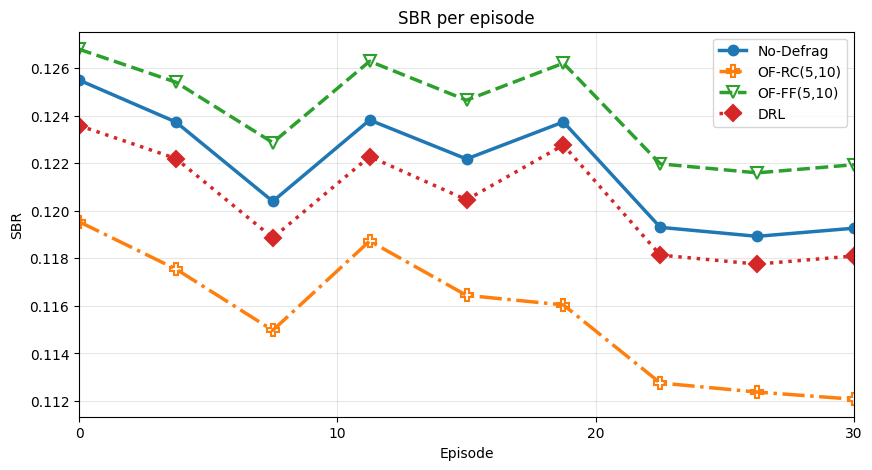

In [44]:
plot_sbr_curves_smoothed(
    res1, 
    methods=("no_defrag", "of_rc2", "of_ff2", "drl"), 
    window=22, 
    p_rc=8, 
    n_rc=4, 
    
    p_rc2=5, 
    n_rc2=10,

    p_ff=8, 
    n_ff=4,  
    
    p_ff2=5, 
    n_ff2=10
    )

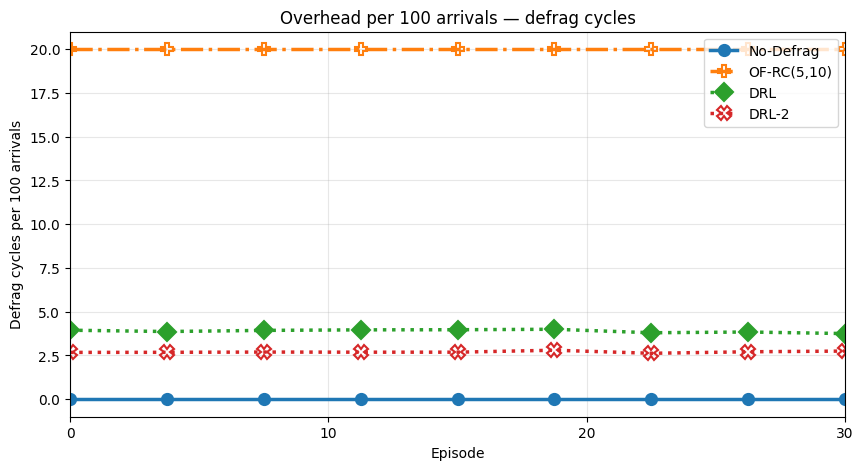

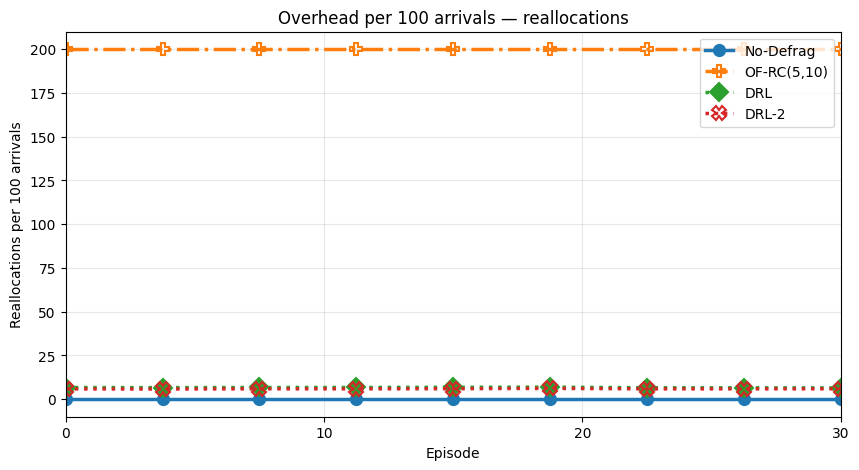

In [46]:
plot_overhead_per_100_arrivals(
    results=res1,
    methods=("no_defrag", "of_rc2", "drl", "drl2"),
    
    of_rc_p=8,
    of_rc_n=4,
    
    of_rc2_p=5,
    of_rc2_n=10,
    
    of_ff_p=8,
    of_ff_n=4,

    of_ff2_p=5,
    of_ff2_n=10,
    
    smooth_window=22,
)

In [ ]:
save_dir = save_benchmark_results(
    res1,
    name="banana3_rc2_ff2_drl",
    params=params,
    methods=("no_defrag", "of_rc2", "of_ff2", "drl"),
)

#Later, even after restarting the kernel:
list_saved_benchmarks()
res5 = load_latest_benchmark()
#or:
res5 = load_benchmark_results("saved_benchmarks/YOUR_FOLDER_NAME")